# Session 4 · A deeper CNN and batch normalization

My basic CNN still missed 26 of 45 scratches. I wanted to see whether a feature covering a larger part of the crop would help. I added one block, measured that change, then trained the deeper model again with batch normalization. That gave me two separate comparisons.

In [1]:
from pathlib import Path
from copy import deepcopy
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

seed = 42
torch.manual_seed(seed)
torch.set_num_threads(min(4, torch.get_num_threads()))
artifacts = Path("Artifacts")
manifest_path = artifacts / "split_manifest.csv"
manifest = pd.read_csv(manifest_path)
classes = sorted(manifest.loc[manifest.split == "train", "label"].unique().tolist())
class_ids = list(range(len(classes)))
label_id = {name: i for i, name in enumerate(classes)}
assert len(classes) == 6
train_rows = manifest.loc[manifest.split == "train"].reset_index(drop=True)
val_rows = manifest.loc[manifest.split == "validation"].reset_index(drop=True)
assert train_rows.label.value_counts().reindex(classes).eq(210).all()
assert val_rows.label.value_counts().reindex(classes).eq(45).all()
assert set(train_rows.pixel_sha256).isdisjoint(val_rows.pixel_sha256)
print(f"{len(train_rows)} training images, {len(val_rows)} validation images. Running on CPU.")

manifest_digest = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
basic_saved = torch.load(artifacts / "basic_cnn.pt", map_location="cpu", weights_only=True)
basic = json.loads((artifacts / "basic_cnn_validation.json").read_text(encoding="utf-8"))
for previous in (basic, basic_saved):
    assert previous["classes"] == classes and previous["manifest_sha256"] == manifest_digest
assert basic["validation_macro_f1"] == basic_saved["validation_macro_f1"]

1260 training images, 270 validation images. Running on CPU.


In [2]:
def load_images(rows):
    pixels = torch.empty((len(rows), 1, 200, 200), dtype=torch.uint8)
    for index, row in enumerate(rows.itertuples(index=False)):
        with Image.open(row.path) as image:
            if image.size != (200, 200) or image.mode != "L":
                raise ValueError(f"Unexpected image format: {row.path}")
            if hashlib.sha256(image.tobytes()).hexdigest() != row.pixel_sha256:
                raise ValueError(f"Pixel content changed since Session 1: {row.path}")
            pixels[index, 0] = torch.from_numpy(np.array(image))
    targets = torch.tensor(rows.label.map(label_id).tolist(), dtype=torch.long)
    return TensorDataset(pixels, targets)

train_data = load_images(train_rows)
val_data = load_images(val_rows)
mean, std = basic_saved["mean"], basic_saved["std"]

def normalize(pixels):
    return (pixels.float() / 255.0 - mean) / std

batch_size = 64
val_loader = DataLoader(val_data, batch_size=batch_size)
print(f"Training mean {mean:.4f}, standard deviation {std:.4f} on a 0–1 scale.")

Training mean 0.5009, standard deviation 0.2125 on a 0–1 scale.


## How much of the steel one feature can see

After the second pool, each feature covers 19 × 19 input pixels, and adjacent centers are eight pixels apart. A 3 × 3 convolution adds two of those steps, taking the field to 35. The next 2 × 2 pool adds one more step, taking it to 43. Its centers are now 16 pixels apart. The extra block also changes the map resolution, so this experiment measures the whole block’s effect.

In [3]:
def make_deep_cnn(batch_norm):
    layers = []
    for inputs, outputs, kernel, stride in [(1, 8, 5, 2), (8, 16, 3, 1), (16, 16, 3, 1)]:
        layers.append(nn.Conv2d(inputs, outputs, kernel, stride, padding=kernel // 2))
        if batch_norm:
            layers.append(nn.BatchNorm2d(outputs))
        layers.extend([nn.ReLU(), nn.MaxPool2d(2)])
    layers.extend([nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten(), nn.Linear(256, len(classes))])
    return nn.Sequential(*layers).to(memory_format=torch.channels_last)

field, step, width = 1, 1, 200
trace = []
for block, (kernel, stride) in enumerate([(5, 2), (3, 1), (3, 1)], start=1):
    for operation, k, s, padding in [("conv", kernel, stride, kernel // 2), ("pool", 2, 2, 0)]:
        field += (k - 1) * step
        step *= s
        width = (width + 2 * padding - k) // s + 1
        trace.append([block, operation, width, field, step])
display(pd.DataFrame(trace, columns=["Block", "Operation", "Map width", "Field width", "Center step"]))
assert (width, field, step) == (12, 43, 16)

,Block,Operation,Map width,Field width,Center step
0,1,conv,100,5,2
1,1,pool,50,7,4
2,2,conv,50,15,4
3,2,pool,25,19,8
4,3,conv,25,35,8
5,3,pool,12,43,16


## Two runs with the same starting weights

I reset the seed and minibatch order for each deeper run. The convolution and classifier weights started identically. For the second run I inserted batch normalization before each ReLU. It estimates a mean and variance per channel during training, applies a learned scale and offset, and uses running statistics at evaluation.

In [4]:
epochs, learning_rate = 20, 0.0003
loss_fn = nn.CrossEntropyLoss()

@torch.inference_mode()
def validate(network):
    network.eval()
    outputs = torch.cat([network(normalize(x)) for x, _ in val_loader])
    targets = val_data.tensors[1]
    predictions = outputs.argmax(dim=1)
    score = f1_score(targets.numpy(), predictions.numpy(), labels=class_ids,
                     average="macro", zero_division=0)
    return loss_fn(outputs, targets).item(), float(score), predictions

def run_experiment(name, batch_norm):
    torch.manual_seed(seed)
    model = make_deep_cnn(batch_norm)
    loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []
    best_score = -1.0
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for pixels, targets in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(normalize(pixels)), targets)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(targets)
        val_loss, score, predictions = validate(model)
        history.append({"epoch": epoch, "train_loss": total_loss / len(train_data),
                        "validation_loss": val_loss, "validation_macro_f1": score})
        if score > best_score:
            best_epoch, best_score = epoch, score
            best_state = deepcopy(model.state_dict())
            best_predictions = predictions.clone()
        if epoch == 1 or epoch % 5 == 0:
            print(f"{name}, epoch {epoch:2d}: validation macro F1 {score:.4f}")

    checkpoint = artifacts / f"{name}.pt"
    payload = {"state_dict": best_state, "architecture": name, "batch_norm": batch_norm,
               "channels": [8, 16, 16], "classes": classes, "input_shape": [1, 200, 200],
               "mean": mean, "std": std, "seed": seed, "epoch": best_epoch,
               "validation_macro_f1": best_score, "manifest_sha256": manifest_digest}
    temporary = checkpoint.with_suffix(".tmp")
    torch.save(payload, temporary)
    temporary.replace(checkpoint)
    saved = torch.load(checkpoint, map_location="cpu", weights_only=True)
    restored = make_deep_cnn(saved["batch_norm"])
    restored.load_state_dict(saved["state_dict"])
    _, score, predicted = validate(restored)
    assert torch.equal(predicted, best_predictions) and score == best_score
    actual = val_data.tensors[1].numpy()
    report = classification_report(actual, predicted.numpy(), labels=class_ids,
                                   target_names=classes, output_dict=True, zero_division=0)
    metrics = {"model": name, "parameters": sum(p.numel() for p in restored.parameters()),
               "batch_norm": batch_norm, "learning_rate": learning_rate, "batch_size": batch_size,
               "seed": seed, "best_epoch": best_epoch, "validation_macro_f1": score,
               "classes": classes, "validation_report": report, "history": history,
               "validation_confusion_matrix": confusion_matrix(actual, predicted, labels=class_ids).tolist(),
               "manifest_sha256": manifest_digest}
    (artifacts / f"{name}_validation.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
    return metrics, restored

In [5]:
deep, plain_model = run_experiment("deep_cnn", batch_norm=False)

deep_cnn, epoch  1: validation macro F1 0.0601


deep_cnn, epoch  5: validation macro F1 0.4666


deep_cnn, epoch 10: validation macro F1 0.6549


deep_cnn, epoch 15: validation macro F1 0.8047


deep_cnn, epoch 20: validation macro F1 0.8480


In [6]:
deep_bn, bn_model = run_experiment("deep_cnn_bn", batch_norm=True)

deep_cnn_bn, epoch  1: validation macro F1 0.1036


deep_cnn_bn, epoch  5: validation macro F1 0.8141


deep_cnn_bn, epoch 10: validation macro F1 0.8680


deep_cnn_bn, epoch 15: validation macro F1 0.9303


deep_cnn_bn, epoch 20: validation macro F1 0.9335


## What happened to scratches

Depth alone took validation macro F1 from 0.7118 to 0.8480 and scratch recall from 19 to 26 out of 45. With batch normalization, the deeper model reached 0.9408 and found 39 scratches. Its scratch precision was 0.975, so 39 of its 40 scratch predictions were right.

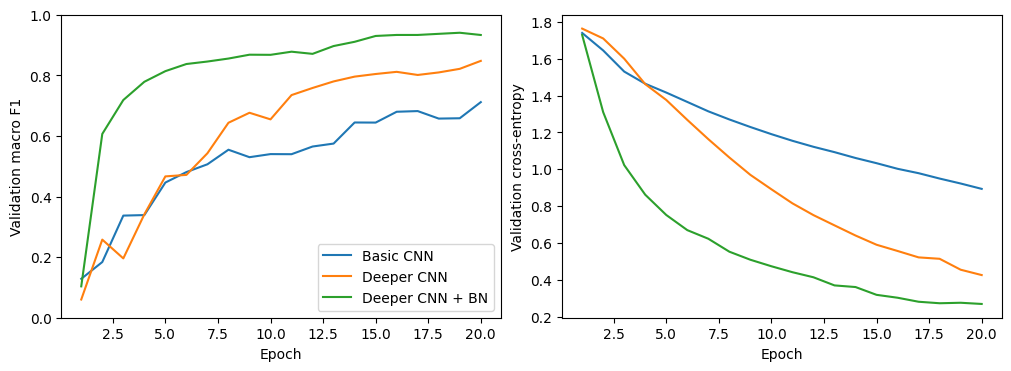

,Parameters,Best epoch,Macro F1,Correct / 270,Scratches / 45,Scratch precision
Model,,,,,,
Basic CNN,2918,20,0.7118,193,19,0.6552
Deeper CNN,5238,20,0.8480,230,26,0.8966
Deeper CNN + BN,5318,19,0.9408,254,39,0.9750


Predicted for true scratches,crazing,inclusion,patches,pitted_surface,rolled_in_scale,scratches
Basic CNN,0,13,0,1,12,19
Deeper CNN,0,9,0,2,8,26
Deeper CNN + BN,0,4,0,2,0,39


Predicted label,crazing,inclusion,patches,pitted_surface,rolled_in_scale,scratches
True label · Deeper CNN,,,,,,
crazing,42,0,2,0,1,0
inclusion,0,41,0,4,0,0
patches,1,0,43,1,0,0
pitted_surface,0,4,1,39,1,0
rolled_in_scale,0,0,2,1,39,3
scratches,0,9,0,2,8,26


Predicted label,crazing,inclusion,patches,pitted_surface,rolled_in_scale,scratches
True label · Deeper CNN + BN,,,,,,
crazing,45,0,0,0,0,0
inclusion,0,40,0,5,0,0
patches,3,0,42,0,0,0
pitted_surface,0,1,0,43,0,1
rolled_in_scale,0,0,0,0,45,0
scratches,0,4,0,2,0,39


In [7]:
runs = {"Basic CNN": basic, "Deeper CNN": deep, "Deeper CNN + BN": deep_bn}
summary = []
scratch_rows = []
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for label, run in runs.items():
    matrix = np.asarray(run["validation_confusion_matrix"])
    scratch = matrix[label_id["scratches"]]
    assert matrix.sum() == 270 and scratch.sum() == 45
    summary.append([label, run["parameters"], run["best_epoch"], run["validation_macro_f1"],
                    matrix.trace(), scratch[label_id["scratches"]],
                    run["validation_report"]["scratches"]["precision"]])
    scratch_rows.append(scratch)
    history = pd.DataFrame(run["history"])
    axes[0].plot(history.epoch, history.validation_macro_f1, label=label)
    axes[1].plot(history.epoch, history.validation_loss, label=label)
axes[0].set(xlabel="Epoch", ylabel="Validation macro F1", ylim=(0, 1))
axes[1].set(xlabel="Epoch", ylabel="Validation cross-entropy")
axes[0].legend()
plt.show()
display(pd.DataFrame(summary, columns=["Model", "Parameters", "Best epoch", "Macro F1",
                                      "Correct / 270", "Scratches / 45", "Scratch precision"])
        .set_index("Model").round(4))
display(pd.DataFrame(scratch_rows, index=list(runs), columns=pd.Index(classes, name="Predicted for true scratches")))
for label in list(runs)[1:]:
    display(pd.DataFrame(runs[label]["validation_confusion_matrix"],
                         index=pd.Index(classes, name=f"True label · {label}"),
                         columns=pd.Index(classes, name="Predicted label")))

## One channel in training and evaluation mode

I passed the same batch through a copy of the selected model twice and inspected channel 0. The raw convolution output stayed fixed. Switching the normalization layer between current-batch and running statistics changed the values reaching the ReLU.

In [8]:
batch = normalize(train_data.tensors[0][torch.randperm(len(train_data),
                  generator=torch.Generator().manual_seed(seed))[:batch_size]])
demo = deepcopy(bn_model)
with torch.inference_mode():
    raw = demo[0](batch)
    demo.eval()
    using_running_stats = demo[1](raw)
    demo.train()
    using_batch_stats = demo[1](raw)
    channel = 0
    rows = []
    for label, values in [("Conv output", raw), ("BN · training mode", using_batch_stats),
                          ("BN · evaluation mode", using_running_stats)]:
        values = values[:, channel]
        rows.append([label, values.mean().item(), values.std(unbiased=False).item()])
display(pd.DataFrame(rows, columns=["Channel 0", "Mean", "Standard deviation"]).set_index("Channel 0").round(4))

,Mean,Standard deviation
Channel 0,,
Conv output,-0.1649,0.1518
BN · training mode,0.0282,1.0013
BN · evaluation mode,0.1183,0.9521


## The model I carried forward

The normalized CNN made zero scratch-to-rolled-in-scale errors on validation. Four scratches still went to inclusion and two to pitted surface. I kept this 5,318-parameter model as the control for the augmentation runs.